## 1. Setup & Imports

In [1]:
import pandas as pd #import pandas
import numpy as np #import numpy
import matplotlib.pyplot as plt #import matplotlib
import sys
sys.path.append("..") 
from src.feature_engineering import convert_date_columns, create_transaction_difference

In [2]:
data_test = pd.read_csv("../data/bank_transactions_data_2.csv")
data_test = convert_date_columns(data_test)
data_test = create_transaction_difference(data_test)

data_test[data_test["AccountID"] == "AC00001"][["AccountID", "TransactionDate_dt", "PrevTransactionDate_calc", "Transaction_diff"]]

,AccountID,TransactionDate_dt,PrevTransactionDate_calc,Transaction_diff
0,AC00001,2023-09-15 17:00:20,NaT,NaN
1,AC00001,2023-11-14 16:56:34,2023-09-15 17:00:20,1439.94


## 2. Load Data

In [3]:
data = pd.read_csv("../data/bank_transactions_data_2.csv") #read the data from csv file

## 3. First Exploration

In [4]:
data.info() #get the information about the data
print(data.describe()) #get the statistical summary of the data
data.isnull().sum() #check for missing values

<class 'pandas.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   str    
 1   AccountID                2512 non-null   str    
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   str    
 4   TransactionType          2512 non-null   str    
 5   Location                 2512 non-null   str    
 6   DeviceID                 2512 non-null   str    
 7   IP Address               2512 non-null   str    
 8   MerchantID               2512 non-null   str    
 9   Channel                  2512 non-null   str    
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   str    
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance           2512 non-n

TransactionID              0
AccountID                  0
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
dtype: int64

## 4. Convert Datetime format

In [5]:
data["TransactionDate_dt"] = pd.to_datetime(data["TransactionDate"]) # needed as datetime to calculate time differences later
data["PreviousTransactionDate_dt"] = pd.to_datetime(data["PreviousTransactionDate"]) # needed as datetime to calculate time differences later

## 5. Account ID Analysis

In [6]:
print("Unique Account IDs:", data['AccountID'].nunique()) #explore how many unique account IDs are present in the dataset
print("Total Rows:", len(data))

Unique Account IDs: 495
Total Rows: 2512


## 6. Feature Engineering (Exploration)

In [7]:
data_transaction = data.sort_values(by=['AccountID', 'TransactionDate_dt'])
data_transaction = data_transaction.reset_index(drop=True) 
data_transaction["PrevTransactionDate_calc"] = data_transaction.groupby("AccountID")["TransactionDate_dt"].shift(1) #calculate the previous transaction date for each account   

## 6.1 Explore Transaction Diffference <br>
Create "Transaction_diff" column

In [8]:
data_transaction["Transaction_diff"] = ((data_transaction["TransactionDate_dt"]-data_transaction["PrevTransactionDate_calc"])/pd.Timedelta(hours=1)).round(2)
data_transaction[['AccountID', 'TransactionDate_dt', 'PrevTransactionDate_calc', 'Transaction_diff']].head(15)


,AccountID,TransactionDate_dt,PrevTransactionDate_calc,Transaction_diff
0,AC00001,2023-09-15 17:00:20,NaT,NaN
1,AC00001,2023-11-14 16:56:34,2023-09-15 17:00:20,1439.94
2,AC00002,2023-01-10 16:00:32,NaT,NaN
3,AC00002,2023-02-28 16:36:58,2023-01-10 16:00:32,1176.61
4,AC00002,2023-05-05 16:35:44,2023-02-28 16:36:58,1583.98
5,AC00002,2023-05-16 16:07:30,2023-05-05 16:35:44,263.53
6,AC00002,2023-07-24 16:14:05,2023-05-16 16:07:30,1656.11
7,AC00002,2023-09-11 17:52:59,2023-07-24 16:14:05,1177.65
8,AC00002,2023-12-21 17:00:50,2023-09-11 17:52:59,2423.13
9,AC00003,2023-01-02 16:45:05,NaT,NaN


## 6.2 Epxlore unusal Location <br>
First we need to create the Home Location to check if the location is usual or not <br>
No usefull insight, 75% of the Location is unusual --> not a good parameter (probaply randomly generated)

In [9]:
data_transaction["HomeLocation"] = data_transaction.groupby("AccountID")["Location"].transform(lambda x: x.mode()[0]) 
data_transaction["is_unusal_Location"] = (data_transaction["Location"] != data_transaction["HomeLocation"]).astype(int)
print(data_transaction[["HomeLocation", "Location","is_unusal_Location"]].head(15))

data_transaction["is_unusal_Location"].mean()
data_transaction.groupby("AccountID")["Location"].nunique().describe() #unique location are not suitable for fraud detection as some accounts have multiple locations, so we will try IP address instead


   HomeLocation     Location  is_unusal_Location
0       Atlanta       Denver                   1
1       Atlanta      Atlanta                   0
2     Charlotte    San Diego                   1
3     Charlotte  Los Angeles                   1
4     Charlotte      El Paso                   1
5     Charlotte       Dallas                   1
6     Charlotte    Milwaukee                   1
7     Charlotte    Las Vegas                   1
8     Charlotte    Charlotte                   0
9     Baltimore  San Antonio                   1
10    Baltimore     Columbus                   1
11    Baltimore    Baltimore                   0
12    Baltimore   Fort Worth                   1
13    Baltimore        Miami                   1
14     Columbus         Mesa                   1


count    495.000000
mean       4.783838
std        2.115047
min        1.000000
25%        3.000000
50%        5.000000
75%        6.000000
max       11.000000
Name: Location, dtype: float64

## 6.3 Explore IP Adress <br>
We have 5 unique IDs with an averge of 5 transaction per account --> not a good parameter (probaply randomly generated)

In [10]:
data_transaction.groupby("AccountID")["IP Address"].nunique().describe() #the same problem occurs with IP addresses 


count    495.000000
mean       5.048485
std        2.273254
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       12.000000
Name: IP Address, dtype: float64

In [11]:
columns_to_check = ["Location", "IP Address", "DeviceID", "MerchantID", "Channel", "TransactionType"]

results = {}
for col in columns_to_check:
    results[col] = {
        "AvgUniquePerAccount": data_transaction.groupby("AccountID")[col].nunique().mean(),
        "TotalUniqueOverall": data_transaction[col].nunique()
    }

summary = pd.DataFrame.from_dict(results, orient="index")
print(summary)


                 AvgUniquePerAccount  TotalUniqueOverall
Location                    4.783838                  43
IP Address                  5.048485                 592
DeviceID                    5.050505                 681
MerchantID                  4.941414                 100
Channel                     2.428283                   3
TransactionType             1.676768                   2


## 6.4 Explore Account Balance

In [12]:
data_transaction["PrevAccountBalance"] = data_transaction.groupby("AccountID")["AccountBalance"].shift(1)
data_transaction["BalanceDiff"] = data_transaction["AccountBalance"] - data_transaction["PrevAccountBalance"]
data_transaction_test = data_transaction.dropna(subset=["BalanceDiff"])
data_transaction_test["direction_matches"] =((data_transaction_test["BalanceDiff"] > 0) & (data_transaction_test["TransactionType"] == "Credit")) | ((data_transaction_test["BalanceDiff"] < 0) & (data_transaction_test["TransactionType"] == "Debit"))

print(data_transaction_test[data_transaction_test["AccountID"] == "AC00002"].sort_values("TransactionDate_dt")[
    ["TransactionDate_dt", "TransactionType", "TransactionAmount", "AccountBalance", "PrevAccountBalance", "BalanceDiff","direction_matches"]
])
print(1 - data_transaction_test["direction_matches"].mean())

   TransactionDate_dt TransactionType  TransactionAmount  AccountBalance  \
3 2023-02-28 16:36:58           Debit              59.32         5750.89   
4 2023-05-05 16:35:44           Debit              12.62         6420.47   
5 2023-05-16 16:07:30           Debit             263.99         4175.02   
6 2023-07-24 16:14:05           Debit             395.16         5340.73   
7 2023-09-11 17:52:59           Debit             331.66         7216.30   
8 2023-12-21 17:00:50          Credit             516.47         1305.06   

   PrevAccountBalance  BalanceDiff  direction_matches  
3             1154.48      4596.41              False  
4             5750.89       669.58              False  
5             6420.47     -2245.45               True  
6             4175.02      1165.71              False  
7             5340.73      1875.57              False  
8             7216.30     -5911.24              False  
0.4992563212692117


## 6.5 Customer Age & Occupation

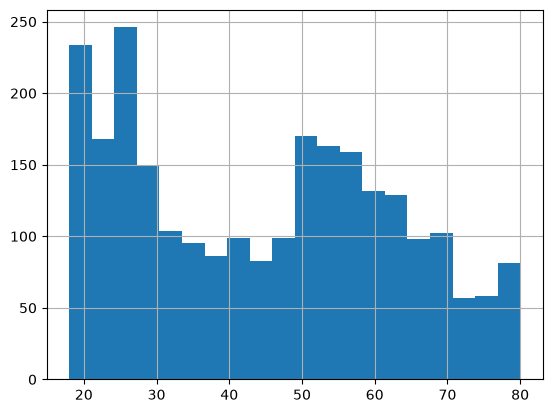

,count,mean,std,min,25%,50%,75%,max
CustomerOccupation,,,,,,,,
Doctor,631.0,49.581616,12.449233,29.0,39.0,50.0,61.0,70.0
Engineer,625.0,42.648000,10.273859,26.0,34.0,42.0,51.0,60.0
Retired,599.0,65.315526,8.701033,51.0,57.0,65.0,73.0,80.0
Student,657.0,23.068493,3.134174,18.0,20.0,23.0,26.0,28.0


In [13]:
data_transaction["CustomerAge"].hist(bins=20)
plt.show()

data_transaction["CustomerOccupation"].value_counts()
data_transaction.groupby("CustomerOccupation")["CustomerAge"].describe()

## 6.6 Transaction Duration & Channel

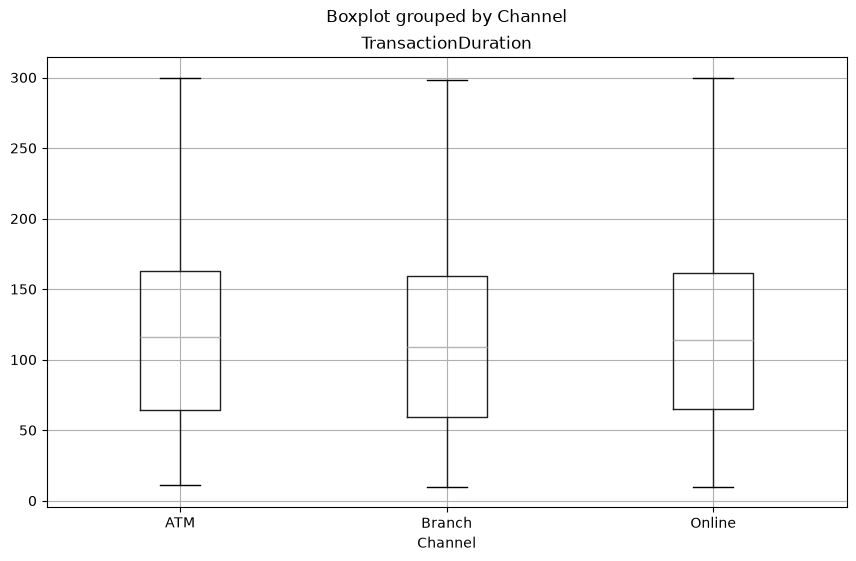

In [14]:
data_transaction.groupby("Channel")["TransactionDuration"].describe()
fig, ax = plt.subplots(figsize=(10, 6))
data_transaction.boxplot(column="TransactionDuration", by="Channel", ax=ax)
plt.show()